# Exercise 2 – How unpredictable is a sporting event?

### Question 1

**Select three sporting events: two with the same number of outcomes and one with a different number.**

### Answer 1

The sporting events selected with the same number of outcomes are:
- Barcelona - Inter Milan, Champions League Semifinal
    - Odds: Home Win $1.44$, Draw $4.50$, Away Win $7.50$
- Inter Milan - AC Milan, Serie A
    - Odds: Home Win $2.15$, Draw $3.40$, Away Win $3.50$

The match with differents outcomes is:
- Jannik Sinner - Carlos Alcaraz, Wimbledon Final
    - Odds: Player 1 Win $1.91$, Player 2 Win $1.91$

### Question 2
From decimal odds $o_i$, form $q_i = \frac{1}{o_i}$ and normalize $p_i = \frac{q_i}{\sum_j q_j}$.

### Answer 2

#### 1. Barcelona vs. Inter Milan (Champions League Semifinal)

**Unnormalized Probabilities ($q_i$)**
* $q_1 = \frac{1}{1.44} \approx 0.69444$
* $q_2 = \frac{1}{4.50} \approx 0.22222$
* $q_3 = \frac{1}{7.50} \approx 0.13333$

**Normalized Probabilities ($p_i$)**
* $p_{\text{Home}} = \frac{0.69444}{1.05000} \approx 0.66138 \quad \mathbf{(66.14\%)}$
* $p_{\text{Draw}} = \frac{0.22222}{1.05000} \approx 0.21164 \quad \mathbf{(21.16\%)}$
* $p_{\text{Away}} = \frac{0.13333}{1.05000} \approx 0.12698 \quad \mathbf{(12.70\%)}$

#### 2. Inter Milan vs. AC Milan (Serie A)

**Unnormalized Probabilities ($q_i$)**
* $q_1 = \frac{1}{2.15} \approx 0.46512$
* $q_2 = \frac{1}{3.40} \approx 0.29412$
* $q_3 = \frac{1}{3.50} \approx 0.28571$


**Normalized Probabilities ($p_i$)**
* $p_{\text{Home}} = \frac{0.46512}{1.04495} \approx 0.44511 \quad \mathbf{(44.51\%)}$
* $p_{\text{Draw}} = \frac{0.29412}{1.04495} \approx 0.28147 \quad \mathbf{(28.15\%)}$
* $p_{\text{Away}} = \frac{0.28571}{1.04495} \approx 0.27342 \quad \mathbf{(27.34\%)}$

#### 3. Jannik Sinner vs. Carlos Alcaraz (Wimbledon Final)

**Unnormalized Probabilities ($q_i$)**
* $q_1 = \frac{1}{1.91} \approx 0.52356$
* $q_2 = \frac{1}{1.91} \approx 0.52356$


**Normalized Probabilities ($p_i$)**
* $p_{\text{Player 1}} = \frac{0.52356}{1.04712} = 0.50000 \quad \mathbf{(50.00\%)}$
* $p_{\text{Player 2}} = \frac{0.52356}{1.04712} = 0.50000 \quad \mathbf{(50.00\%)}$


## Question 3
Plot the three pmfs and compute $H(X)$.

## Answer 3

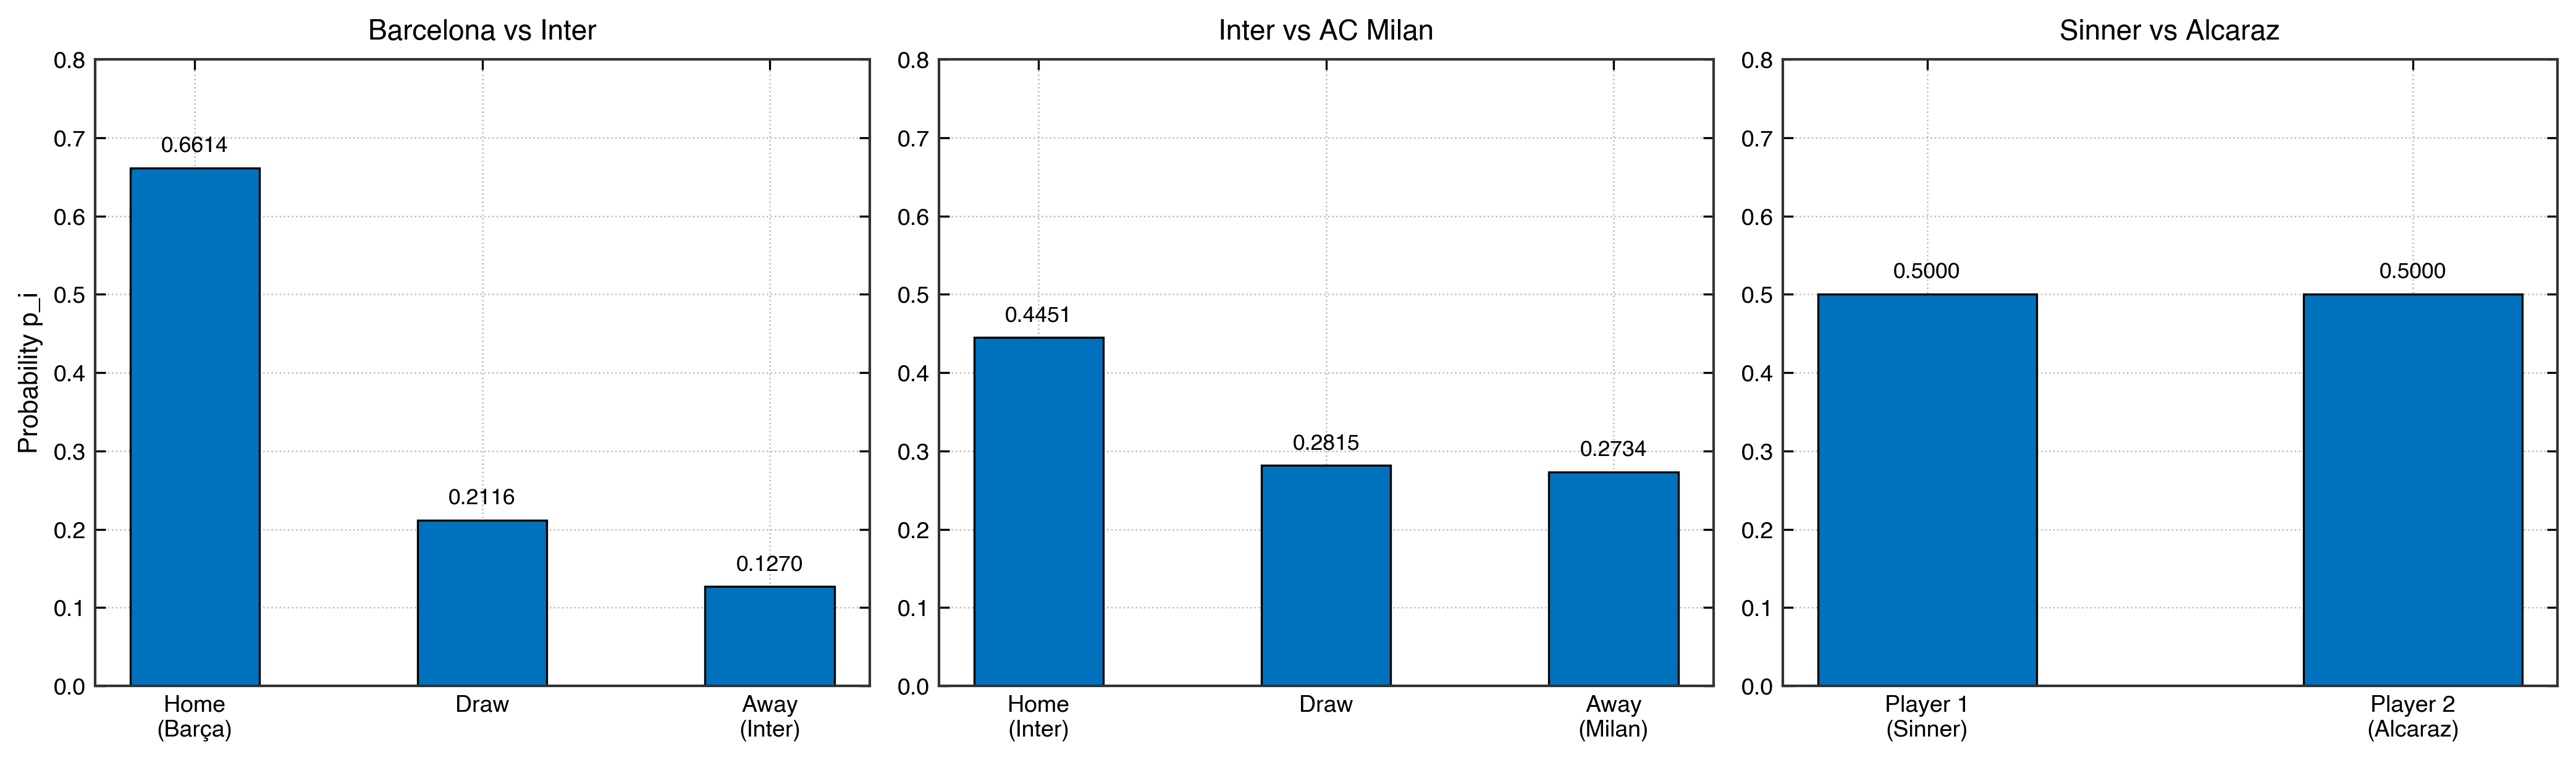

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define Odds
odds_barca_inter = np.array([1.44, 4.50, 7.50])
odds_inter_milan = np.array([2.15, 3.40, 3.50])
odds_sinner_alcaraz = np.array([1.91, 1.91])

# 2. Compute Normalized Probabilities p_i
p1 = (1 / odds_barca_inter) / np.sum(1 / odds_barca_inter)
p2 = (1 / odds_inter_milan) / np.sum(1 / odds_inter_milan)
p3 = (1 / odds_sinner_alcaraz) / np.sum(1 / odds_sinner_alcaraz)

def shannon_entropy(p):
    return -np.sum(p * np.log2(p))

H1, H2, H3 = shannon_entropy(p1), shannon_entropy(p2), shannon_entropy(p3)

# 3. Apply MATLAB Style Configuration
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['mathtext.fontset'] = 'cm'

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), dpi=300)

events = [
    ("Barcelona vs Inter", p1, ['Home\n(Barça)', 'Draw', 'Away\n(Inter)']),
    ("Inter vs AC Milan", p2, ['Home\n(Inter)', 'Draw', 'Away\n(Milan)']),
    ("Sinner vs Alcaraz", p3, ['Player 1\n(Sinner)', 'Player 2\n(Alcaraz)'])
]

# Standard MATLAB default plot color
matlab_blue = '#0072BD'

for idx, (title, p, labels) in enumerate(events):
    ax = axes[idx]
    
    # MATLAB bar style: single solid color with distinct black outlines
    bars = ax.bar(labels, p, color=matlab_blue, edgecolor='black', linewidth=0.8, width=0.45)
    
    ax.set_title(f"{title}", fontsize=11, pad=8)
    if idx == 0:
        ax.set_ylabel('Probability p_i', fontsize=10)
    ax.set_ylim(0, 0.8)
    
    # MATLAB grid & box style
    ax.grid(True, which='both', linestyle=':', linewidth=0.6, color='#a0a0a0', alpha=0.7)
    ax.set_axisbelow(True)
    
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color('#333333')
        spine.set_linewidth(1.0)
        
    # MATLAB tick directions (pointing inward)
    ax.tick_params(direction='in', top=True, right=True, length=4, width=0.8, labelsize=9)
    
    # Add exact numerical values on top of bars
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2.0, height + 0.015,
                f'{height:.4f}', ha='center', va='bottom', fontsize=8.5)

plt.tight_layout()
plt.show()

In [9]:
print("H(X_1)= ", H1)
print("H(X_2)= ", H2)
print("H(X_3)= ", H3)

H(X_1)=  1.2466907872075113
H(X_2)=  1.546095355803682
H(X_3)=  1.0


## Question 4
Also compute the normalized entropy $H_{norm} = H(X)/\log_2 M$.

## Answer 4

In [11]:
import numpy as np

# Calculated probability distributions
p1 = np.array([0.66137566, 0.21164021, 0.12698413])
p2 = np.array([0.44510941, 0.28146624, 0.27342435])
p3 = np.array([0.5, 0.5])

def compute_normalized_entropy(p):
    M = len(p)
    H = -np.sum(p * np.log2(p))
    H_max = np.log2(M)
    return H, H_max, H / H_max

distributions = {
    "Barcelona vs Inter": p1,
    "Inter vs AC Milan": p2,
    "Sinner vs Alcaraz": p3
}

for name, p in distributions.items():
    H, H_max, H_norm = compute_normalized_entropy(p)
    print(f"{name:20s} | H(X): {H:.4f} bits | H_norm: {H_norm:.4f}")

Barcelona vs Inter   | H(X): 1.2467 bits | H_norm: 0.7866
Inter vs AC Milan    | H(X): 1.5461 bits | H_norm: 0.9755
Sinner vs Alcaraz    | H(X): 1.0000 bits | H_norm: 1.0000


## Question 5
Discuss the results

## Answer 5
TO DO

## Question 6
Discuss what changes when the number of possible outcomes M is different.

## Answer 6

---

# Exercise 4 – Maximum entropy under mean constraints

Invent a real-world example representing four possible computational costs (you MUST present an example not only the 4 numerical values). (Order for increasing values of $x_i$)

## Question 1
Compute numerically the MaxEnt pmf for three different values of $µ$.

## Answer 1
